# K-Means Visualization | Assignment 7
**Juan Luna Santibanez**

Miami Dade College | CAI2100C-2267-6908 | Machine Learning Foundations

**Professor Beth Muturi**

**Goal:** Show how the Iris observations are grouped when K = 4, 5 and 9. K = 3 is the classroom reference.

## 1. Load and inspect the Iris dataset
The four measurements describe each flower. The species column is excluded from K-Means training.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from pathlib import Path
import urllib.request

URL = "https://raw.githubusercontent.com/SupaHumano/CAI2100C-KMeans-Visualization/main/data/IRIS.csv"
candidates = [Path("data/IRIS.csv"), Path("../data/IRIS.csv"), Path("IRIS.csv"), Path("/content/IRIS.csv")]
candidates += list(Path("/kaggle/input").glob("**/IRIS.csv")) if Path("/kaggle/input").exists() else []
source = next((p for p in candidates if p.is_file()), None)
if source is None:
    source = Path("IRIS.csv")
    urllib.request.urlretrieve(URL, source)
df = pd.read_csv(source)
feature_columns = ["sepal_length","sepal_width","petal_length","petal_width"]
assert len(df) == 150 and not df[feature_columns].isnull().any().any()
X = df[feature_columns].to_numpy()
print(f"Loaded {len(df)} Iris flowers and {len(feature_columns)} numeric features from {source}")
display(df.head())


Loaded 150 Iris flowers and 4 numeric features from data/IRIS.csv


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [2]:
print('Shape:', X.shape)
print('Missing values:', df[feature_columns].isnull().sum().to_dict())
print('Ranges:')
display(df[feature_columns].describe().round(2))

Shape: (150, 4)
Missing values: {'sepal_length': 0, 'sepal_width': 0, 'petal_length': 0, 'petal_width': 0}
Ranges:


,sepal_length,sepal_width,petal_length,petal_width
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


## 2. Elbow method and classroom reference
The elbow curve describes how within-cluster variation changes with K. It does not prove how many biological species exist.

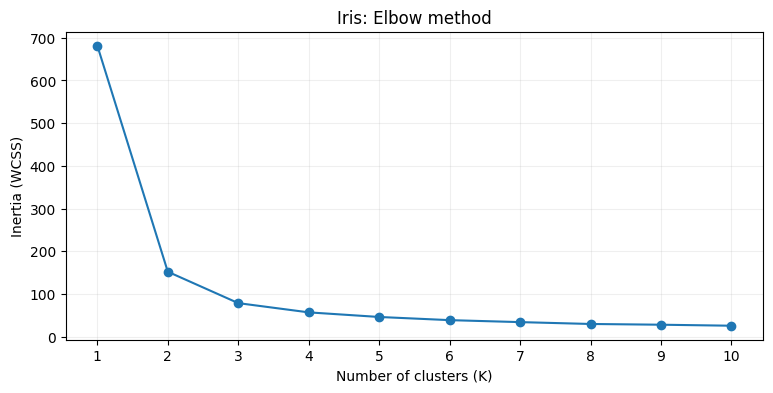

In [3]:
inertia_curve=[]
for k in range(1,11):
    model=KMeans(n_clusters=k, init='k-means++', n_init=10, max_iter=300, random_state=0)
    model.fit(X)
    inertia_curve.append(model.inertia_)
plt.figure(figsize=(9,4))
plt.plot(range(1,11),inertia_curve,marker='o')
plt.xticks(range(1,11)); plt.grid(alpha=.2)
plt.xlabel('Number of clusters (K)'); plt.ylabel('Inertia (WCSS)'); plt.title('Iris: Elbow method')
plt.show()

## 3. Compare the three assigned values
A model is fitted independently for each requested K using the same four features and initialization controls.

In [4]:
models = {}
for k in (3,4,5,9):
    model=KMeans(n_clusters=k, init='k-means++', n_init=10, max_iter=300, random_state=0)
    labels=model.fit_predict(X)
    assert len(labels)==150 and model.cluster_centers_.shape==(k,4)
    models[k] = (model, labels)
    print(f'K={k} | inertia={model.inertia_:.3f} | group sizes={np.bincount(labels, minlength=k).tolist()}')

K=3 | inertia=78.851 | group sizes=[62, 50, 38]
K=4 | inertia=57.228 | group sizes=[28, 50, 32, 40]
K=5 | inertia=46.446 | group sizes=[12, 50, 25, 24, 39]
K=9 | inertia=28.333 | group sizes=[28, 22, 21, 18, 22, 7, 6, 20, 6]


## 4. Required visualization: K = 4
Each colored point represents one flower. A black cross shows a fitted center, projected onto petal length and petal width.

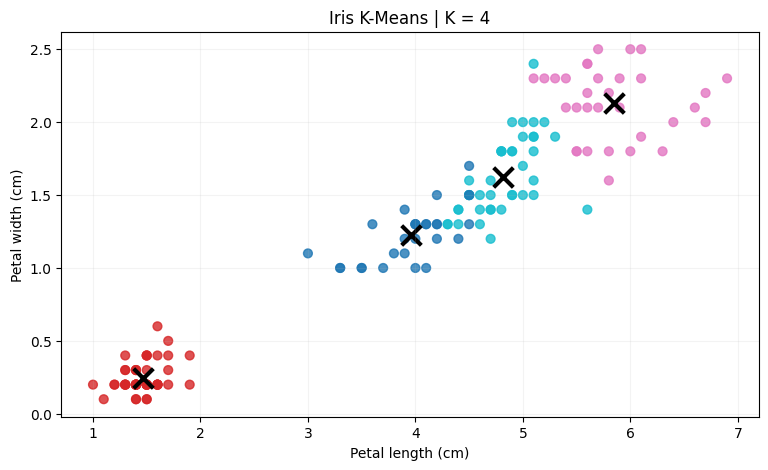

In [5]:
k=4
model, labels=models[k]
plt.figure(figsize=(9,5))
plt.scatter(X[:,2],X[:,3],c=labels,cmap='tab10',s=40,alpha=.8)
plt.scatter(model.cluster_centers_[:,2],model.cluster_centers_[:,3],marker='x',s=200,c='black',linewidths=3)
plt.title('Iris K-Means | K = 4'); plt.xlabel('Petal length (cm)'); plt.ylabel('Petal width (cm)'); plt.grid(alpha=.15); plt.show()

## 5. Required visualization: K = 5
Compare the new group membership and center positions against K = 4.

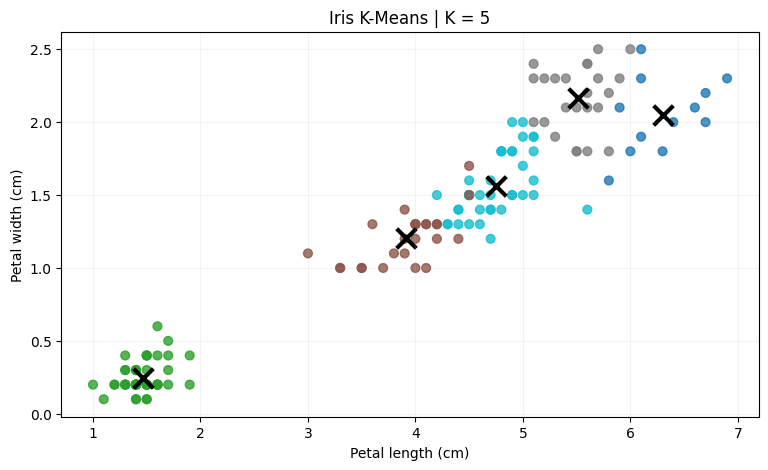

In [6]:
k=5
model, labels=models[k]
plt.figure(figsize=(9,5))
plt.scatter(X[:,2],X[:,3],c=labels,cmap='tab10',s=40,alpha=.8)
plt.scatter(model.cluster_centers_[:,2],model.cluster_centers_[:,3],marker='x',s=200,c='black',linewidths=3)
plt.title('Iris K-Means | K = 5'); plt.xlabel('Petal length (cm)'); plt.ylabel('Petal width (cm)'); plt.grid(alpha=.15); plt.show()

## 6. Required visualization: K = 9
Nine groups do not mean nine Iris species. Cluster counts are a modeling choice.

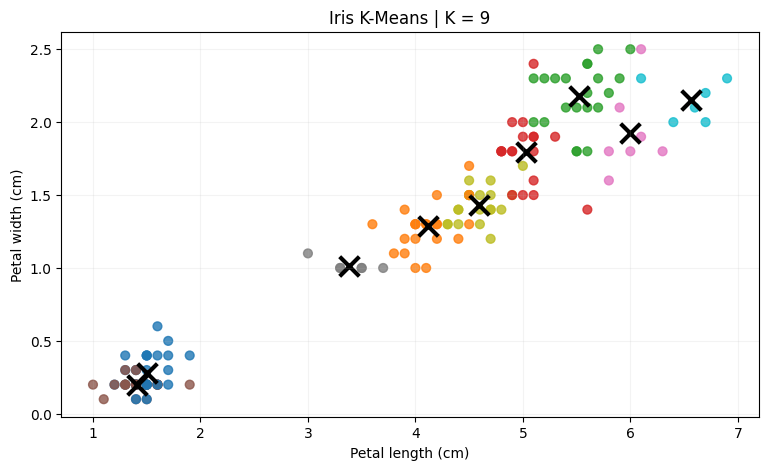

In [7]:
k=9
model, labels=models[k]
plt.figure(figsize=(9,5))
plt.scatter(X[:,2],X[:,3],c=labels,cmap='tab10',s=40,alpha=.8)
plt.scatter(model.cluster_centers_[:,2],model.cluster_centers_[:,3],marker='x',s=200,c='black',linewidths=3)
plt.title('Iris K-Means | K = 9'); plt.xlabel('Petal length (cm)'); plt.ylabel('Petal width (cm)'); plt.grid(alpha=.15); plt.show()

## 7. Conclusion
Increasing K splits the same flowers into more groups. Inertia usually decreases because the model has more centroids to represent the data. The groups should not be interpreted as distinct species without independent evidence. This experiment demonstrates K-Means visualization for K = 4, 5 and 9.